# 1D and 2D Random Walks

**References:** `Notes/lec_sde.pdf`, `Notes/randomwalk_1D.ipynb` (Professor code), `Notes/Quiz2/06_Random_Walks_1D_and_2D.ipynb`

## Concept & Formulas
- **1D Random Walk:** $x_n = x_{n-1} + \eta_n$, where step $\eta_n = +1$ (prob $p_r$) or $-1$ (prob $p_l = 1 - p_r$).
- **Unbiased 1D Walk ($p_r = p_l = 1/2$):**
  - Mean displacement: $\langle x_n \rangle = 0$.
  - Mean Squared Displacement (MSD): $\langle x_n^2 \rangle = n$ (spread grows as $\sqrt{n}$).
  - Connection to diffusion: $\langle x(t)^2 \rangle = 2Dt$ with $D = \frac{\Delta x^2}{2\Delta t}$.
- **2D Unbiased Walk:** $\mathbf{R}_n = x_n \hat{i} + y_n \hat{j}$, where $x_n, y_n$ take independent $\pm 1$ steps:
  - Mean displacement: $\langle \mathbf{R}_n \rangle = \mathbf{0}$.
  - 2D MSD: $\langle R_n^2 \rangle = \langle x_n^2 \rangle + \langle y_n^2 \rangle = n + n = 2n$.
- **Limitations:** A single random walk trajectory is noisy and jagged; smooth laws like $\langle x_n^2 \rangle = n$ only appear after averaging over many independent realizations ($N_{\text{re}}$).

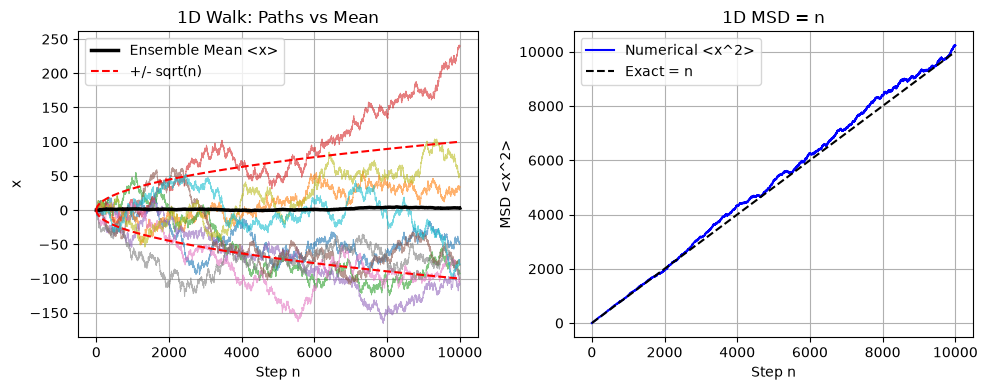

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1D Random Walk: Individual trajectories vs Ensemble Average (Quiz 2 style)
N = 10000          # Number of steps
Nre = 1000         # Number of realizations

msd = np.zeros((N, Nre))
X = np.zeros((N, Nre))

for ire in range(Nre):
    steps = np.where(np.random.rand(N) >= 0.5, 1, -1)
    steps[0] = 0
    x = np.cumsum(steps)
    X[:, ire] = x
    msd[:, ire] = x**2

avgX = np.mean(X, axis=1)
avgMSD = np.mean(msd, axis=1)
steps_axis = np.arange(N)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
for i in range(10):
    plt.plot(steps_axis, X[:, i], lw=0.7, alpha=0.6)
plt.plot(steps_axis, avgX, 'k-', lw=2.5, label='Ensemble Mean <x>')
plt.plot(steps_axis, np.sqrt(steps_axis), 'r--', label='+/- sqrt(n)')
plt.plot(steps_axis, -np.sqrt(steps_axis), 'r--')
plt.xlabel('Step n'); plt.ylabel('x'); plt.title('1D Walk: Paths vs Mean')
plt.legend(); plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(steps_axis, avgMSD, 'b-', label='Numerical <x^2>')
plt.plot(steps_axis, steps_axis, 'k--', label='Exact = n')
plt.xlabel('Step n'); plt.ylabel('MSD <x^2>'); plt.title('1D MSD = n')
plt.legend(); plt.grid(True)
plt.tight_layout()
plt.show()

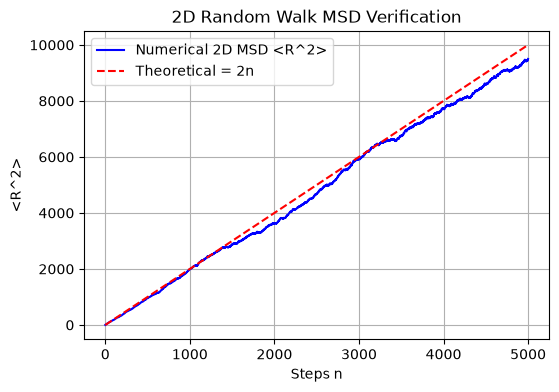

In [2]:
# 2D Random Walk MSD Verification (<R^2> = 2n)
N = 5000
Nre = 500
R_sq = np.zeros((N, Nre))

for ire in range(Nre):
    step_x = np.where(np.random.rand(N) >= 0.5, 1, -1); step_x[0] = 0
    step_y = np.where(np.random.rand(N) >= 0.5, 1, -1); step_y[0] = 0
    x = np.cumsum(step_x)
    y = np.cumsum(step_y)
    R_sq[:, ire] = x**2 + y**2

avg_R_sq = np.mean(R_sq, axis=1)
steps = np.arange(N)

plt.figure(figsize=(6, 4))
plt.plot(steps, avg_R_sq, 'b-', label='Numerical 2D MSD <R^2>')
plt.plot(steps, 2 * steps, 'r--', label='Theoretical = 2n')
plt.xlabel('Steps n'); plt.ylabel('<R^2>')
plt.title('2D Random Walk MSD Verification')
plt.legend(); plt.grid(True)
plt.show()

---
## Professor's In-Class Code (`Notes/randomwalk_1D.ipynb`)
Exact code from the professor's notebook (`N = 20000` steps, `Nre = 1000` realizations).

[ 0.000e+00 -1.200e-02  8.000e-03 ...  8.134e+00  8.144e+00  8.146e+00]


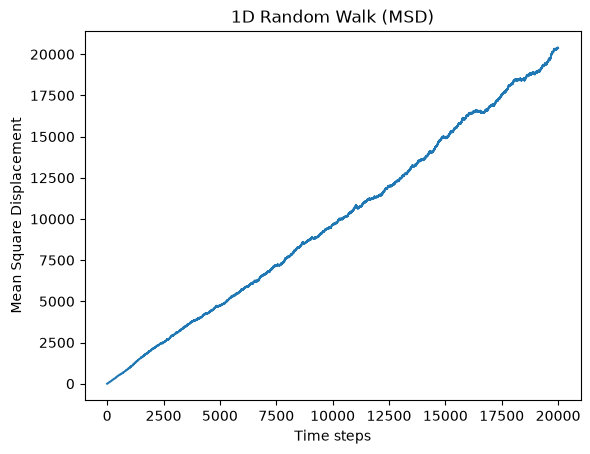

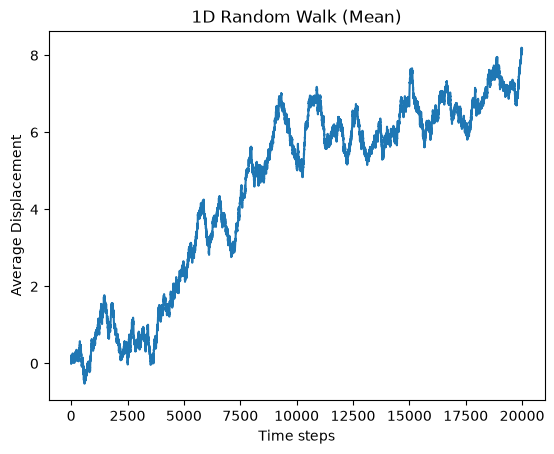

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
N = 20000       # Number of steps/iterations
Nre = 1000      # Number of realizations

# Initialize arrays
x = np.zeros(N)                 # Displacement of the walker
msd = np.zeros((N, Nre))        # Mean square displacement
X = np.zeros((N, Nre))          # Displacement for different realizations

# Realization loop
for ire in range(Nre):

    x[0] = 0 # Initial position
    
    # Temporal iteration loop
    for i in range(1, N):

        rd = np.random.rand()  # Random number for displacement

        if rd >= 0.5:
            x[i] = x[i-1] + 1
        else:
            x[i] = x[i-1] - 1

    # Store displacement and MSD
    msd[:, ire] = x**2
    X[:, ire] = x

# Calculate averages over realizations
avgX = np.mean(X, axis=1)
avgMSD = np.mean(msd, axis=1)

print(avgX)
# Plot mean square displacement
plt.plot(avgMSD)
plt.xlabel('Time steps')
plt.ylabel('Mean Square Displacement')
plt.title('1D Random Walk (MSD)')
plt.figure()
plt.plot(avgX)
plt.xlabel('Time steps')
plt.ylabel('Average Displacement')
plt.title('1D Random Walk (Mean)')
plt.show()